In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, binom

rng = np.random.default_rng(42)

R = 200_000
T = 5.0
q = 0.4

lambda_star = 3.0
lambda_sky = 2.0

lambda_star_det = q * lambda_star
lambda_sky_det = q * lambda_sky
lambda_total = lambda_star_det + lambda_sky_det

print(f"Detected star rate: {lambda_star_det:.2f} photons/s")
print(f"Detected sky rate:  {lambda_sky_det:.2f} photons/s")
print(f"Total rate:         {lambda_total:.2f} photons/s")

Detected star rate: 1.20 photons/s
Detected sky rate:  0.80 photons/s
Total rate:         2.00 photons/s


In [7]:
star_emitted = rng.poisson(lambda_star * T, size=R)
sky_emitted = rng.poisson(lambda_sky * T, size=R)

star_det_1 = rng.binomial(star_emitted, q)
sky_det_1 = rng.binomial(sky_emitted, q)

total_det_1 = star_det_1 + sky_det_1

In [8]:
star_det_2 = rng.poisson(lambda_star_det * T, size=R)
sky_det_2 = rng.poisson(lambda_sky_det * T, size=R)

total_det_2 = star_det_2 + sky_det_2

In [9]:
def summarize_counts(star, sky, label):
    total = star + sky

    print(f"\n--- {label} ---")
    print(f"{'Count':<12} {'Mean':>10} {'Variance':>12}")
    print("-" * 36)

    for name, values in [
        ("Star", star),
        ("Sky", sky),
        ("Total", total)
    ]:
        print(f"{name:<12} {np.mean(values):>10.4f} "
              f"{np.var(values):>12.4f}")

    corr = np.corrcoef(star, sky)[0, 1]
    print(f"\nCorrelation (star, sky): {corr:.5f}")


summarize_counts(star_det_1, sky_det_1, "Method 1: Thinning")
summarize_counts(star_det_2, sky_det_2, "Method 2: Direct")


--- Method 1: Thinning ---
Count              Mean     Variance
------------------------------------
Star             5.9917       5.9632
Sky              4.0005       3.9971
Total            9.9922       9.9277

Correlation (star, sky): -0.00333

--- Method 2: Direct ---
Count              Mean     Variance
------------------------------------
Star             5.9967       5.9738
Sky              3.9900       3.9969
Total            9.9867      10.0067

Correlation (star, sky): 0.00368


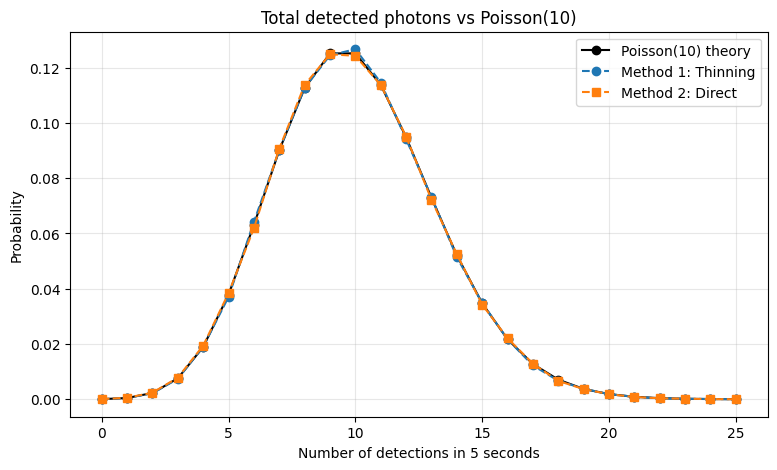

In [10]:
k = np.arange(0, 26)

pmf_theory = poisson.pmf(k, mu=10)

pmf_method_1 = np.bincount(
    total_det_1, minlength=len(k)
)[:len(k)] / R

pmf_method_2 = np.bincount(
    total_det_2, minlength=len(k)
)[:len(k)] / R

plt.figure(figsize=(9, 5))

plt.plot(k, pmf_theory, "ko-", label="Poisson(10) theory")
plt.plot(k, pmf_method_1, "o--", label="Method 1: Thinning")
plt.plot(k, pmf_method_2, "s--", label="Method 2: Direct")

plt.xlabel("Number of detections in 5 seconds")
plt.ylabel("Probability")
plt.title("Total detected photons vs Poisson(10)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
def conditional_probability(star, total):
    mask = total == 10

    probability = np.mean(star[mask] == 6)

    print(f"Windows with 10 detections: {np.sum(mask)}")
    print(f"Estimated P(6 star | 10 total): {probability:.5f}")

    return probability


print("Method 1:")
p1 = conditional_probability(star_det_1, total_det_1)

print("\nMethod 2:")
p2 = conditional_probability(star_det_2, total_det_2)

p_theory = binom.pmf(6, n=10, p=0.6)

print(f"\nTheoretical probability: {p_theory:.5f}")

Method 1:
Windows with 10 detections: 25324
Estimated P(6 star | 10 total): 0.24945

Method 2:
Windows with 10 detections: 24848
Estimated P(6 star | 10 total): 0.25221

Theoretical probability: 0.25082


In [13]:
def conditional_probability(star, total):
    mask = total == 10

    probability = np.mean(star[mask] == 6)

    print(f"Windows with 10 detections: {np.sum(mask)}")
    print(f"Estimated P(6 star | 10 total): {probability:.5f}")

    return probability


print("Method 1:")
p1 = conditional_probability(star_det_1, total_det_1)

print("\nMethod 2:")
p2 = conditional_probability(star_det_2, total_det_2)

p_theory = binom.pmf(6, n=10, p=0.6)

print(f"\nTheoretical probability: {p_theory:.5f}")

Method 1:
Windows with 10 detections: 25324
Estimated P(6 star | 10 total): 0.24945

Method 2:
Windows with 10 detections: 24848
Estimated P(6 star | 10 total): 0.25221

Theoretical probability: 0.25082


In [14]:
T_star = rng.exponential(scale=1/lambda_star_det, size=R)
T_sky = rng.exponential(scale=1/lambda_sky_det, size=R)

T_first = np.minimum(T_star, T_sky)

star_first = T_star < T_sky

M = np.maximum(T_star, T_sky)

In [15]:
p_star_first = np.mean(star_first)

p_star_first_1s = np.mean(
    star_first & (T_first <= 1)
)

mean_M = np.mean(M)

p_star_theory = lambda_star_det / lambda_total

p_star_1s_theory = p_star_theory * (
    1 - np.exp(-lambda_total)
)

mean_M_theory = (
    1/lambda_star_det
    + 1/lambda_sky_det
    - 1/lambda_total
)

print(f"P(star first):")
print(f"  Simulated:   {p_star_first:.5f}")
print(f"  Theoretical: {p_star_theory:.5f}")

print(f"\nP(star first and within 1 s):")
print(f"  Simulated:   {p_star_first_1s:.5f}")
print(f"  Theoretical: {p_star_1s_theory:.5f}")

print(f"\nE[M]:")
print(f"  Simulated:   {mean_M:.5f} s")
print(f"  Theoretical: {mean_M_theory:.5f} s")

P(star first):
  Simulated:   0.59920
  Theoretical: 0.60000

P(star first and within 1 s):
  Simulated:   0.51782
  Theoretical: 0.51880

E[M]:
  Simulated:   1.58414 s
  Theoretical: 1.58333 s


In [16]:
I = star_first.astype(int)

corr_time_type = np.corrcoef(T_first, I)[0, 1]

print(f"Correlation (first time, type): {corr_time_type:.5f}")
print("Theoretical correlation:       0.00000")

Correlation (first time, type): 0.00224
Theoretical correlation:       0.00000


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.default_rng(42)

n_days = 30
hours_per_day = 24
T = n_days * hours_per_day  # 720 hours

lambda_max = 20

a_true = 12
b_true = 8
phi_true = 16

def intensity(t, a=12, b=8, phi=16):
    return a + b * np.cos(np.pi * (t - phi) / 12)

In [18]:
n_proposed = rng.poisson(lambda_max * T)

proposed_times = np.sort(
    rng.uniform(0, T, size=n_proposed)
)

keep_prob = intensity(proposed_times) / lambda_max

keep = rng.random(n_proposed) < keep_prob

arrival_times = proposed_times[keep]

n_kept = len(arrival_times)
fraction_kept = n_kept / n_proposed

print(f"Proposed arrivals: {n_proposed}")
print(f"Kept arrivals:     {n_kept}")
print(f"Fraction kept:     {fraction_kept:.4f}")
print(f"Theoretical fraction kept: {12/20:.4f}")

Proposed arrivals: 14502
Kept arrivals:     8767
Fraction kept:     0.6045
Theoretical fraction kept: 0.6000


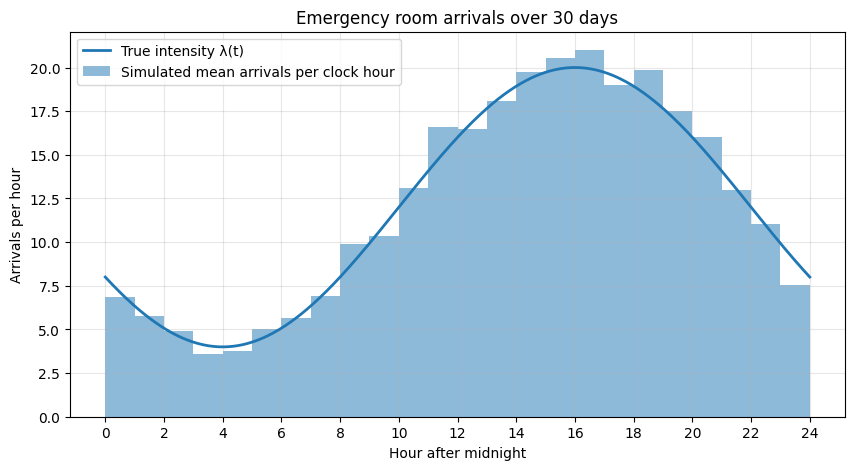

In [19]:
clock_times = arrival_times % 24

hourly_counts, _ = np.histogram(
    clock_times, bins=np.arange(25)
)

hourly_mean = hourly_counts / n_days

t_plot = np.linspace(0, 24, 500)
lambda_plot = intensity(t_plot)

plt.figure(figsize=(10, 5))

plt.bar(
    np.arange(24),
    hourly_mean,
    width=1,
    alpha=0.5,
    align="edge",
    label="Simulated mean arrivals per clock hour"
)

plt.plot(
    t_plot,
    lambda_plot,
    linewidth=2,
    label="True intensity λ(t)"
)

plt.xlabel("Hour after midnight")
plt.ylabel("Arrivals per hour")
plt.title("Emergency room arrivals over 30 days")
plt.xticks(np.arange(0, 25, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [20]:
day_index = (arrival_times // 24).astype(int)

mask_3_4 = (clock_times >= 3) & (clock_times < 4)

counts_3_4 = np.bincount(
    day_index[mask_3_4],
    minlength=n_days
)

mean_3_4 = np.mean(counts_3_4)
var_3_4 = np.var(counts_3_4, ddof=1)

print(f"Mean arrivals (3–4 am):     {mean_3_4:.4f}")
print(f"Variance arrivals (3–4 am): {var_3_4:.4f}")
print(f"Theoretical mean:           4.091")
print(f"Theoretical variance:       4.091")

Mean arrivals (3–4 am):     3.6000
Variance arrivals (3–4 am): 4.5241
Theoretical mean:           4.091
Theoretical variance:       4.091


In [21]:
def neg_log_likelihood(params, times, T):
    a, b, phi = params

    rates = intensity(times, a=a, b=b, phi=phi)

    if a <= 0 or b < 0 or b >= a or np.any(rates <= 0):
        return np.inf

    log_likelihood = np.sum(np.log(rates)) - a * T

    return -log_likelihood

In [22]:
initial_guess = [10, 5, 14]

constraints = [
    {"type": "ineq", "fun": lambda p: p[0] - p[1] - 1e-6}
]

bounds = [
    (1e-6, None),  # a
    (0, None),     # b
    (0, 24)        # phi
]

result = minimize(
    neg_log_likelihood,
    x0=initial_guess,
    args=(arrival_times, T),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"maxiter": 2000, "ftol": 1e-9}
)

if not result.success:
    print("Optimization warning:", result.message)

a_hat, b_hat, phi_hat = result.x

print("Estimated parameters:")
print(f"a_hat   = {a_hat:.4f} (true: 12)")
print(f"b_hat   = {b_hat:.4f} (true: 8)")
print(f"phi_hat = {phi_hat:.4f} (true: 16)")

Estimated parameters:
a_hat   = 12.1764 (true: 12)
b_hat   = 8.3563 (true: 8)
phi_hat = 15.9521 (true: 16)


In [23]:
ll_cyclic = -result.fun

lambda_constant = n_kept / T

ll_constant = (
    n_kept * np.log(lambda_constant)
    - lambda_constant * T
)

print(f"Constant-rate MLE: {lambda_constant:.4f} arrivals/hour")
print(f"Cyclic model log-likelihood:   {ll_cyclic:.4f}")
print(f"Constant model log-likelihood: {ll_constant:.4f}")
print(f"Difference:                    {ll_cyclic - ll_constant:.4f}")

Constant-rate MLE: 12.1764 arrivals/hour
Cyclic model log-likelihood:   14257.9752
Constant model log-likelihood: 13146.1054
Difference:                    1111.8697


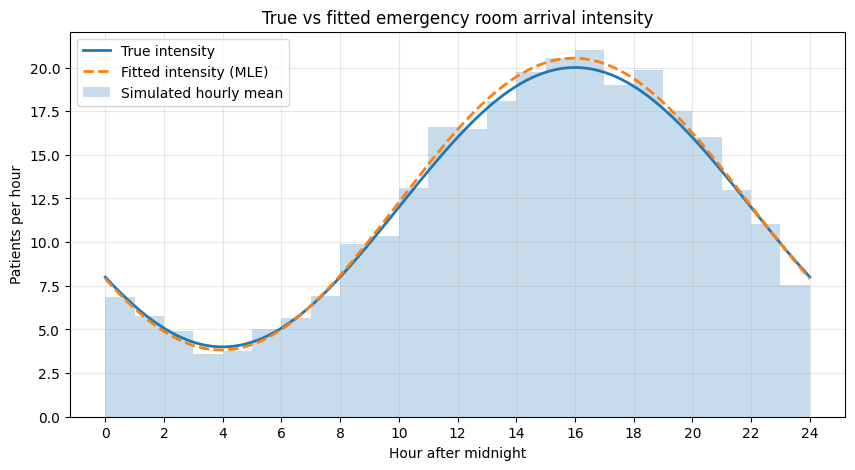

In [24]:
t_plot = np.linspace(0, 24, 500)

true_rate = intensity(t_plot, a_true, b_true, phi_true)
fitted_rate = intensity(t_plot, a_hat, b_hat, phi_hat)

plt.figure(figsize=(10, 5))

plt.plot(
    t_plot, true_rate,
    label="True intensity",
    linewidth=2
)

plt.plot(
    t_plot, fitted_rate,
    "--",
    label="Fitted intensity (MLE)",
    linewidth=2
)

plt.bar(
    np.arange(24),
    hourly_mean,
    width=1,
    align="edge",
    alpha=0.25,
    label="Simulated hourly mean"
)

plt.xlabel("Hour after midnight")
plt.ylabel("Patients per hour")
plt.title("True vs fitted emergency room arrival intensity")
plt.xticks(np.arange(0, 25, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.show()